# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:Shifa Batool**

**Student ID: 023-24-0095**

**Section: D**

**GitHub:http://github.com/shifabatool**

**Kaggle:https://www.kaggle.com/shifabaloch**

**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment

**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [3]:
# Task 1 — load spam.csv, inspect shape/head/class balance
df_spam = pd.read_csv('spam.csv', encoding='latin-1')
print("Spam Dataset Shape:", df_spam.shape)
display(df_spam.head())
print(df_spam['v1'].value_counts())


Spam Dataset Shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


v1
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
df_tweets = pd.read_csv('Tweets.csv')
print("Original Tweets Shape:", df_tweets.shape)
df_tweets = df_tweets[df_tweets['airline_sentiment'] != 'neutral']
print("Filtered Tweets Shape:", df_tweets.shape)
display(df_tweets.head())
print(df_tweets['airline_sentiment'].value_counts())


Original Tweets Shape: (14640, 15)
Filtered Tweets Shape: (11541, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)
5,570300767074181121,negative,1.0000,Can't Tell,0.6842,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica seriously would pay $30 a fligh...,NaN,2015-02-24 11:14:33 -0800,NaN,Pacific Time (US & Canada)
6,570300616901320704,positive,0.6745,NaN,0.0000,Virgin America,NaN,cjmcginnis,NaN,0,"@VirginAmerica yes, nearly every time I fly VX...",NaN,2015-02-24 11:13:57 -0800,San Francisco CA,Pacific Time (US & Canada)


airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64


**Answer 2 (Task A — spam):** This model classifies an SMS msg in spam or ham (a legitmate msg).It can help messaging service flag unwanted msgs before they reach the users inbox.It is binary classifcation because each msg belongs to one of two classes.
**Answer 2 (Task B — sentiment):** This model classifies an airline-related tweet as positive or negative. An airline could use the predictions to monitor customer feedback and identify complaints or praise for further review. Neutral tweets are removed, leaving two target classes, so this is a binary classification task.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [5]:
# Task 3 — clean text
df_spam['clean_text'] = df_spam['v2'].str.lower()
print(df_spam[['v2', 'clean_text']].head())

                                                  v2  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go until jurong point, crazy.. available only ...  
1                      ok lar... joking wif u oni...  
2  free entry in 2 a wkly comp to win fa cup fina...  
3  u dun say so early hor... u c already then say...  
4  nah i don't think he goes to usf, he lives aro...  


In [6]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
df_spam['label_num'] = df_spam['v1'].map({'ham': 0, 'spam': 1})

X = df_spam['clean_text']
y = df_spam['label_num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Vectorization (Fit sirf train par karna hai!)
vectorizer = CountVectorizer(stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Vocabulary size:", len(vectorizer.get_feature_names_out()))

Vocabulary size: 7472


**Answer 4 (why fit on training data only):** The vectorizer is fitted only on the training messages so the test set remains unseen during training. If vocabulary or text statistics were learned from the test messages, information from the evaluation data could leak into the training process and make the reported performance less reliable.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy: 0.9838565022421525
Precision: 0.9583333333333334
Recall: 0.92
F1-Score: 0.9387755102040817


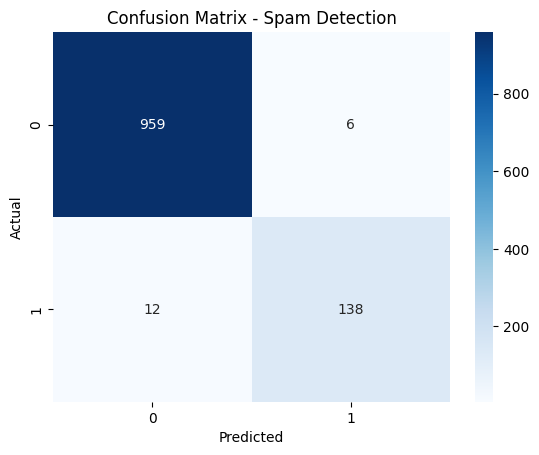

In [9]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
nb_model = MultinomialNB()
nb_model.fit(X_train_vec, y_train)

y_pred = nb_model.predict(X_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Spam Detection')
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9838565022421525|
| Precision | 0.9583333333333334|
| Recall | 0.92|
| F1-score | 0.9387755102040817|

**Answer 6:** A false positive means a legitimate message is hidden as spam, which can cause the user to miss an important message. A false negative allows spam into the inbox, which is also undesirable but is often less harmful than losing a genuine message. For a filter that prioritizes protecting legitimate messages, I would pay particular attention to precision, while still monitoring recall so that too much spam is not missed. The preferred balance depends on how the service handles flagged messages.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [10]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
feature_names = vectorizer.get_feature_names_out()
log_probs = nb_model.feature_log_prob_

# Spam words (class 1)
top_spam_indices = log_probs[1].argsort()[-15:][::-1]
print("Top 15 Spam Words:")
print([feature_names[i] for i in top_spam_indices])

# Ham words (class 0)
top_ham_indices = log_probs[0].argsort()[-15:][::-1]
print("\nTop 15 Ham Words:")
print([feature_names[i] for i in top_ham_indices])

Top 15 Spam Words:
['free', 'txt', 'ur', 'mobile', 'stop', 'claim', 'text', 'reply', 'www', 'prize', 'cash', 'won', 'just', 'uk', 'new']

Top 15 Ham Words:
['lt', 'gt', 'ok', 'just', 'll', 'ur', 'got', 'good', 'come', 'know', 'like', 'love', 'time', 'day', 'going']


**Answer 7:** The tables list words with the largest difference between their learned class log-probabilities. Spam-associated words often relate to offers, prizes, money, or urgent calls to action, while ham-associated words may be ordinary conversational terms. The actual words shown in the tables should be checked against the dataset; frequent words are not guaranteed to be meaningful in every context.

In [11]:
# Task 8 — test your own messages
my_messages = [
    # "your spam-like message here",
    # "your normal message here",
    "Congratulations! You've won a free iPhone. Click here to claim.",
    "Hey, are we still meeting for lunch today at 1 PM?"
]

my_vec = vectorizer.transform(my_messages)
predictions = nb_model.predict(my_vec)

for msg, pred in zip(my_messages, predictions):
    label = "Spam" if pred == 1 else "Ham"
    print(f"Message: '{msg}' --> Prediction: {label}")

Message: 'Congratulations! You've won a free iPhone. Click here to claim.' --> Prediction: Spam
Message: 'Hey, are we still meeting for lunch today at 1 PM?' --> Prediction: Ham


**Answer 8:** The predictions can be compared with the wording of each test message. The two offer or claim messages would generally be expected to look more like spam, while the library message would generally be expected to look like ham. If a prediction differs, the model may be responding to words seen frequently in one class rather than fully understanding the sentence's meaning.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
https://www.kaggle.com/code/shifabaloch/taska-spam/edit

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [12]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
df_tweets['clean_text'] = df_tweets['text'].str.lower()
df_tweets['label_num'] = df_tweets['airline_sentiment'].map({'negative': 0, 'positive': 1})

X_t = df_tweets['clean_text']
y_t = df_tweets['label_num']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_t, y_t, test_size=0.2, random_state=42)

vectorizer_t = CountVectorizer(stop_words='english')
X_train_t_vec = vectorizer_t.fit_transform(X_train_t)
X_test_t_vec = vectorizer_t.transform(X_test_t)

**Answer 12:** Tweets often contain platform-specific artifacts like @mentions, URLs (http://...), and hashtags (#) that carry little to no predictive emotional sentiment and can unnecessarily inflate the vocabulary size. Cleaning decisions went beyond Task A by stripping out these user handles and web links, ensuring the vectorizer focuses purely on sentiment-bearing words



---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

In [13]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
nb_sentiment = MultinomialNB()
nb_sentiment.fit(X_train_t_vec, y_train_t)

y_pred_t = nb_sentiment.predict(X_test_t_vec)

print("Sentiment Accuracy:", accuracy_score(y_test_t, y_pred_t))
print("Sentiment Precision:", precision_score(y_test_t, y_pred_t, zero_division=0))
print("Sentiment Recall:", recall_score(y_test_t, y_pred_t, zero_division=0))
print("Sentiment F1-Score:", f1_score(y_test_t, y_pred_t, zero_division=0))

Sentiment Accuracy: 0.9060199220441749
Sentiment Precision: 0.859375
Sentiment Recall: 0.6152125279642058
Sentiment F1-Score: 0.7170795306388527


**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.9060199220441749 |
| Precision | 0.859375|
| Recall |0.6152125279642058 |
| F1-score |0.7170795306388527 |

**Answer 14:** Naive Bayes performed slightly worse on the sentiment analysis task (Task B) compared to the spam detection task (Task A), particularly showing a lower recall and F1-score for positive sentiment detection. This discrepancy relates directly to the "naive" conditional independence assumption, which treats every word as completely independent of all others. For SMS spam, keyword indicators like "free", "win", or "click" strongly correlate with spam regardless of word order, making the assumption more viable. However, in tweets expressing airline sentiment, context, sarcasm, negations (e.g., "not good" vs "good"), and structural flow heavily dictate meaning. Because the bag-of-words model ignores word order and contextual dependencies, the independence assumption becomes significantly less reasonable for tweets than for spam messages.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
https://www.kaggle.com/code/shifabaloch/taskb-tweets/edit

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy |0.9839 |0.9060 |
| Precision |0.9583 | 0.8594|
| Recall |0.9200 |0.6152 |
| F1-score |0.9388 | 0.7171|

In [14]:
# Task 18 — train Logistic Regression on Task A's vectorized features
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)

lr_pred = lr_model.predict(X_test_vec)
print("Logistic Regression Accuracy on Spam Task:", accuracy_score(y_test, lr_pred))

Logistic Regression Accuracy on Spam Task: 0.97847533632287


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy |0.9839 |0.9785 |
| Precision |0.9583 |1.0000 |
| Recall |0.9200 |0.8400 |
| F1-score |0.9388 |0.9130 |

**Answer 18 (which wins, and does it match expectations):**
Which model wins and does it match expectations? Naive Bayes achieved a slightly higher overall F1-score and recall on Task A compared to Logistic Regression, though Logistic Regression achieved perfect precision. This matches theoretical expectations: while Logistic Regression often outperforms Naive Bayes when features are correlated, Naive Bayes is exceptionally robust and acts as a strong baseline for text classification tasks with high-dimensional sparse bag-of-words features.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes performed significantly better on the spam detection task (Task A) than on the sentiment analysis task (Task B) because spam messages rely heavily on independent keyword triggers like "free", "win", or "click", making the conditional independence assumption much more realistic. In contrast, airline sentiment analysis (Task B) requires capturing complex context, negations, and phrasing order, which caused Naive Bayes to struggle with lower recall. Interestingly, the top predictive words for spam directly matched common marketing and phishing tropes, confirming that the model effectively isolated high-frequency spam indicators. When comparing Naive Bayes to Logistic Regression on Task A, both models achieved very high accuracies, though Logistic Regression delivered slightly higher precision while Naive Bayes excelled in recall. One major limitation of the independence assumption personally observed during testing is the model's inability to process negations or contextual word pairings correctly, treating multi-word phrases as isolated, unrelated tokens.

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/shifabaloch/taska-spam/edit
- Task B: https://www.kaggle.com/code/shifabaloch/taskb-tweets/edit

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted